# Combine tallies from multisystem runs

<!-- index:description -->
Combine OpenMC statepoints from multiple computing systems and plot neutron fluence and standard-error maps.
<!-- /index:description -->

<!-- generated:structure -->
```text
Combine tallies from multisystem runs
├── Find statepoint with the highest batch number
├── Extract data and combine tallies using openmc.StatePoint
└── Symmetry averaging for improved statistics
```
<!-- /generated:structure -->

The simulation was run across 6 computing systems, as reported in [`5_1_runtime_metrics_from_multisystems_runs.ipynb`](5_1_runtime_metrics_from_multisystems_runs.ipynb). The geometry is the Pac-Man model constructed in [`../3_geometry/3_0_ways_to_build_pacman_maze.ipynb`](../3_geometry/3_0_ways_to_build_pacman_maze.ipynb), with the walls assigned to Portland concrete. 2.5 MeV neutrons start isotropically from the origin. The flux mesh tally has a resolution of 25 cm (112 × 124 × 24 bins).

Given that the source–geometry configuration is symmetric about both $x = 0$ and $z = 0$, averaging the corresponding $+x/-x$ and $+z/-z$ mesh bins would improve statistics. However, as will be shown at the end of this notebook, the improvement is modest. Neutrons failed to penetrate the concrete walls. This simulation presents a case for variance reduction and serves as the baseline for subsequent variance-reduction work.

In [1]:
import glob
from pathlib import Path
import re

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np
import openmc
import pandas as pd

plt.style.use('../workbench.mplstyle')

path = Path('analog_ce_reference/runs/analog_ce_seed_*')

### Find statepoint with the highest batch number

In [2]:
spfiles = sorted(glob.glob(str(path / '*_batch_*.h5')))
df_sp = pd.DataFrame(columns=['seed', 'batch'])
for spfile in spfiles:
    seed = int(re.search(r'_seed_(\d+)_batch',spfile).group(1))
    batch = int(re.search(r'_batch_(\d+)\.h5',spfile).group(1))
    df_sp.loc[spfile] = [seed, batch]
df_sp

,seed,batch
analog_ce_reference/runs/analog_ce_seed_000001/analog_ce_seed_000001_batch_2863.h5,1,2863
analog_ce_reference/runs/analog_ce_seed_000001/analog_ce_seed_000001_batch_5726.h5,1,5726
analog_ce_reference/runs/analog_ce_seed_100001/analog_ce_seed_100001_batch_1268.h5,100001,1268
analog_ce_reference/runs/analog_ce_seed_100003/analog_ce_seed_100003_batch_1288.h5,100003,1288
analog_ce_reference/runs/analog_ce_seed_100004/analog_ce_seed_100004_batch_1289.h5,100004,1289
analog_ce_reference/runs/analog_ce_seed_100005/analog_ce_seed_100005_batch_1288.h5,100005,1288
analog_ce_reference/runs/analog_ce_seed_100006/analog_ce_seed_100006_batch_1279.h5,100006,1279
analog_ce_reference/runs/analog_ce_seed_100007/analog_ce_seed_100007_batch_1264.h5,100007,1264
analog_ce_reference/runs/analog_ce_seed_100008/analog_ce_seed_100008_batch_1288.h5,100008,1288
analog_ce_reference/runs/analog_ce_seed_100009/analog_ce_seed_100009_batch_1267.h5,100009,1267


In [3]:
df = pd.DataFrame(columns=['sp_maxbatch'])
for seed, dat in df_sp.groupby('seed'):
    df.loc[seed] = dat['batch'].idxmax()

df

,sp_maxbatch
1,analog_ce_reference/runs/analog_ce_seed_000001...
100001,analog_ce_reference/runs/analog_ce_seed_100001...
100003,analog_ce_reference/runs/analog_ce_seed_100003...
100004,analog_ce_reference/runs/analog_ce_seed_100004...
100005,analog_ce_reference/runs/analog_ce_seed_100005...
100006,analog_ce_reference/runs/analog_ce_seed_100006...
100007,analog_ce_reference/runs/analog_ce_seed_100007...
100008,analog_ce_reference/runs/analog_ce_seed_100008...
100009,analog_ce_reference/runs/analog_ce_seed_100009...
100010,analog_ce_reference/runs/analog_ce_seed_100010...


### Extract data and combine tallies using openmc.StatePoint

During each independent run $k$, OpenMC accumulates a tally estimate $x_{kb}$ for every batch $b$. At the end of the run, the statepoint stores the **sum** $S_{1,k}$ and **sum of squares** $S_{2,k}$ over all batches. Let $n_k$ be the number of batches in run $k$:

$$
S_{1,k} = \sum_{b=1}^{n_k} x_{kb},
\qquad
S_{2,k} = \sum_{b=1}^{n_k} x_{kb}^{2}.
$$

Combining all runs gives the total number of batches $N$, the combined sum $S_1$, the combined sum of squares $S_2$, and the pooled mean tally estimate $\bar{x}$:

$$
N = \sum_k n_k,
\qquad
S_1 = \sum_k S_{1,k},
\qquad
S_2 = \sum_k S_{2,k},
\qquad
\bar{x} = \frac{S_1}{N}.
$$

The estimated variance $s_{\bar X}^{2}$ of the pooled mean, absolute standard error $s_{\bar X}$, and standard-error ratio $r$ are

$$
s_{\bar X}^{2}
= \frac{S_2/N-\bar{x}^{2}}{N-1},
\qquad
s_{\bar X} = \sqrt{s_{\bar X}^{2}},
\qquad
r = \frac{s_{\bar X}}{|\bar{x}|}.
$$

The sums, means, and uncertainties are mesh-shaped arrays, with arithmetic performed elementwise.

OpenMC uses [`std_dev`](https://docs.openmc.org/en/develop/_modules/openmc/lib/tally.html) for the estimated standard deviation of the tally mean. Here, we use **standard error** (`std_err`) for the same quantity, to distinguish it from the standard deviation of individual batch tally estimates.

In [4]:
fields = ['n_particles', 'n_batches', 'current_batch', 'n_realizations']

tallies = {}

for seed, statepoint in df['sp_maxbatch'].items():
    with openmc.StatePoint(statepoint, autolink=False) as sp:
        df.loc[seed, fields] = [getattr(sp, field) for field in fields]

        for tally in sp.tallies.values():
            name = tally.name

            if name not in tallies:
                tallies[name] = {
                    'sum_x': np.zeros_like(tally.sum),
                    'sum_x2': np.zeros_like(tally.sum_sq),
                    'n_total': 0,
                }

            d = tallies[name]
            assert tally.sum.shape == d['sum_x'].shape

            d['sum_x'] += tally.sum
            d['sum_x2'] += tally.sum_sq
            d['n_total'] += tally.num_realizations

combined = {}

for name, d in tallies.items():
    n_total = d['n_total']
    mean = d['sum_x'] / n_total

    variance = (d['sum_x2'] / n_total - mean**2) / (n_total - 1)
    std_err_abs = np.sqrt(np.maximum(variance, 0.0))

    std_err_ratio = np.divide(
        std_err_abs,
        np.abs(mean),
        out=np.full_like(mean, np.inf),
        where=mean != 0,
    )

    combined[name] = {
        'mean': mean,
        'std_err_ratio': std_err_ratio,
        'n_realizations': n_total,
    }

assert df['n_particles'].nunique() == 1
df['total_particles'] = df['n_particles'] * df['current_batch']

cols = ['current_batch', 'n_realizations']
assert df[['n_batches', *cols]].nunique(axis=1).eq(1).all()
df.drop(columns=cols, inplace=True)

df

,sp_maxbatch,n_particles,n_batches,total_particles
1,analog_ce_reference/runs/analog_ce_seed_000001...,1000000.0,5726.0,5.726000e+09
100001,analog_ce_reference/runs/analog_ce_seed_100001...,1000000.0,1268.0,1.268000e+09
100003,analog_ce_reference/runs/analog_ce_seed_100003...,1000000.0,1288.0,1.288000e+09
100004,analog_ce_reference/runs/analog_ce_seed_100004...,1000000.0,1289.0,1.289000e+09
100005,analog_ce_reference/runs/analog_ce_seed_100005...,1000000.0,1288.0,1.288000e+09
100006,analog_ce_reference/runs/analog_ce_seed_100006...,1000000.0,1279.0,1.279000e+09
100007,analog_ce_reference/runs/analog_ce_seed_100007...,1000000.0,1264.0,1.264000e+09
100008,analog_ce_reference/runs/analog_ce_seed_100008...,1000000.0,1288.0,1.288000e+09
100009,analog_ce_reference/runs/analog_ce_seed_100009...,1000000.0,1267.0,1.267000e+09
100010,analog_ce_reference/runs/analog_ce_seed_100010...,1000000.0,1179.0,1.179000e+09


### Symmetry averaging for improved statistics

The source–geometry configuration is symmetric about both $x = 0$ and $z = 0$. We average corresponding $+x/-x$ and $+z/-z$ mesh bins for improved statistics.

OpenMC's mesh `flux` tally is a track-length tally. Dividing by the voxel volume gives the **neutron fluence per history**, in cm$^{-2}$.

The mirrored bins can be correlated within a run. We calculate the standard error of the symmetry-averaged estimates from the independent-seed results, rather than combining the original per-bin standard errors as though the bins were independent.

Let $F_k(x,y,z)$ be the fluence estimate from independent run $k$ after dividing the mesh tally by voxel volume. Symmetry averaging about $x = 0$ and then $z = 0$ gives

$$
F_{k,x\text{-avg}}(x,y,z)
= \frac{F_k(+x,y,z) + F_k(-x,y,z)}{2},
$$

$$
F_{k,xz\text{-avg}}(x,y,z)
= \frac{F_{k,x\text{-avg}}(x,y,+z) + F_{k,x\text{-avg}}(x,y,-z)}{2}.
$$

The statepoints do not store the covariance between mirrored bins explicitly. Instead, the code first averages mirrored bins within each independent run, then estimates the standard error from those **independent-seed estimates**. With $K$ independent runs, weights $w_k = n_k$ (the number of batches in run $k$) and $W = \sum_k w_k$:

$$
\bar{F}_{\text{avg}}
= \frac{\sum_k w_k F_{k,\text{avg}}}{W},
\qquad
s_{\bar X,\text{avg}}^{2}
= \frac{\sum_k w_k\left(F_{k,\text{avg}} - \bar{F}_{\text{avg}}\right)^2}{(K-1)W},
\qquad
r_{\text{avg}} = \frac{s_{\bar X,\text{avg}}}{|\bar{F}_{\text{avg}}|}.
$$

This uses the variability between independent seeds to retain any within-run correlations between mirrored bins.

For each map bin, the figure of merit is $\mathrm{FOM}=1/(r^2 t)$, where $t$ is the sum of the execution times of the independent runs.

Total wall time summed over runs: 4.09516e+06 s
XY median FOM before symmetry averaging: 0.0004638 s^-1
XY median FOM after symmetry averaging: 0.0007427 s^-1
XZ median FOM before symmetry averaging: 8.543e-05 s^-1
XZ median FOM after symmetry averaging: 0.0001677 s^-1


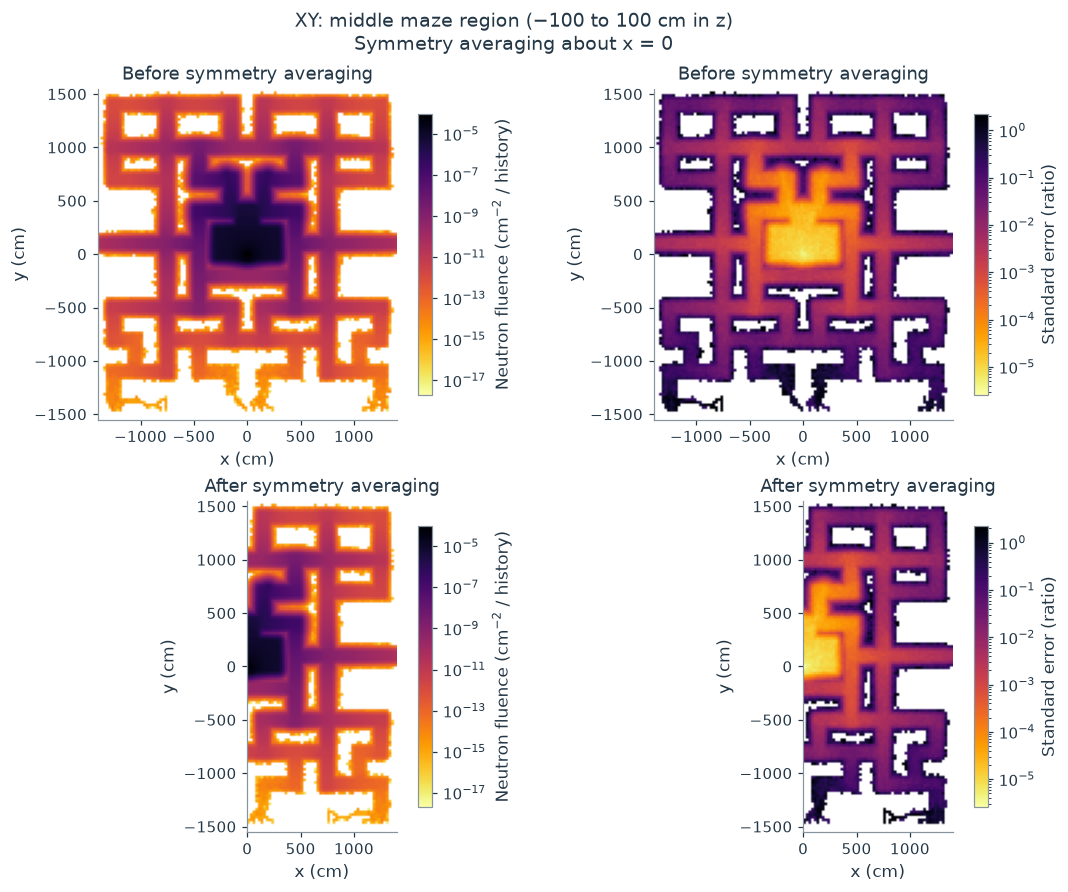

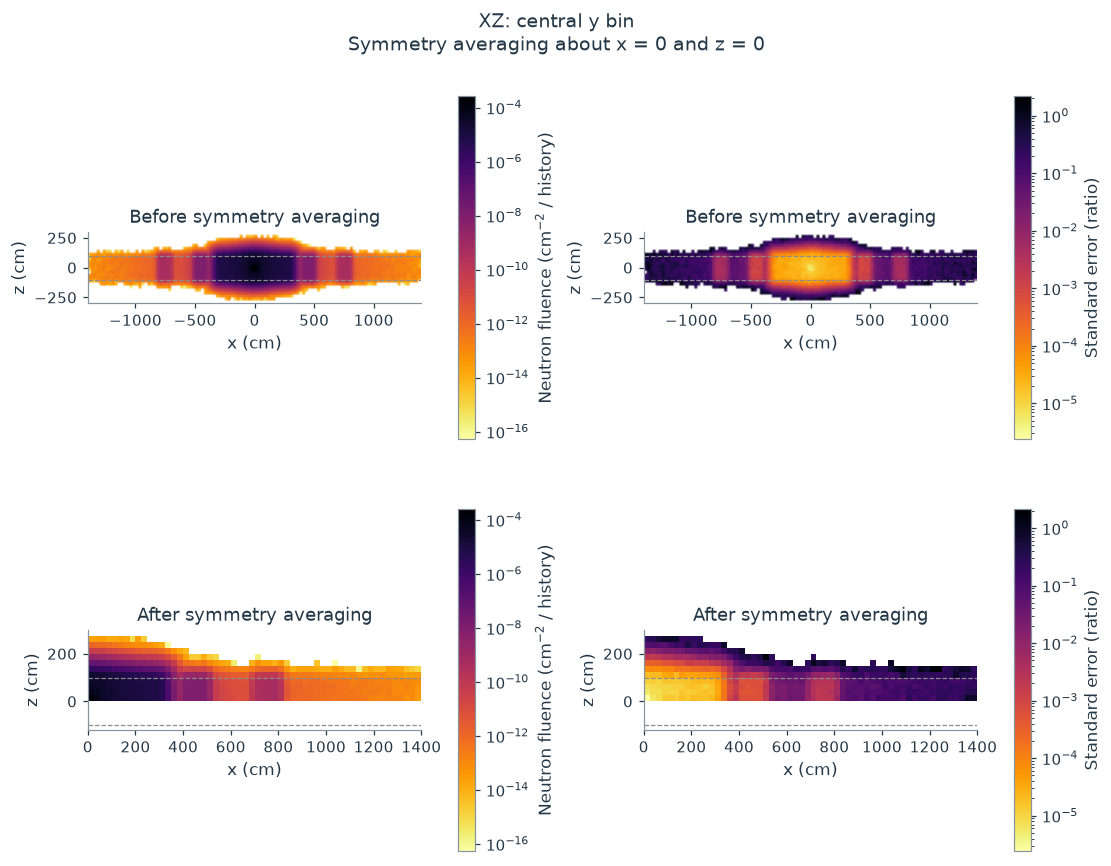

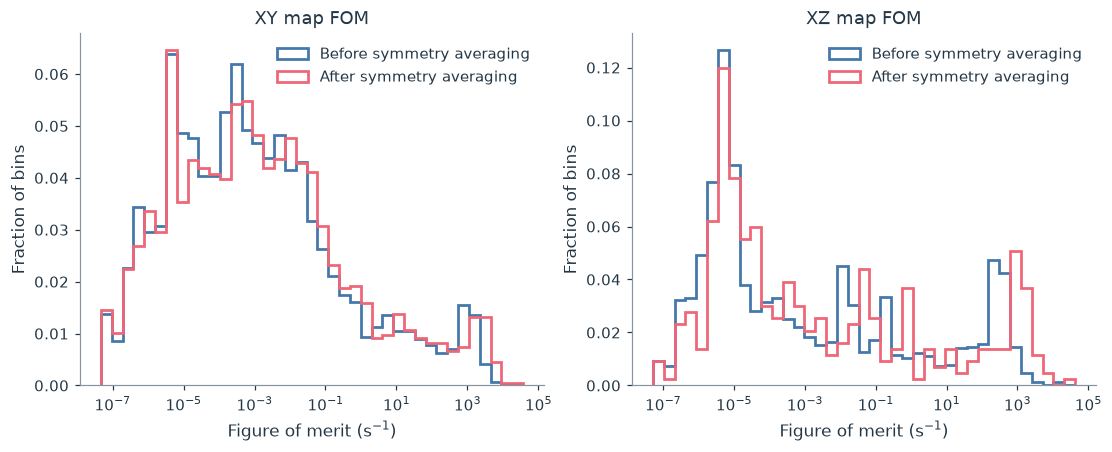

In [5]:
tally_name = 'global_flux'

with openmc.StatePoint(df['sp_maxbatch'].iloc[0], autolink=False) as sp:
    tally = sp.get_tally(name=tally_name)
    mesh = tally.find_filter(openmc.MeshFilter).mesh

nx, ny, nz = mesh.dimension
x = np.linspace(mesh.lower_left[0], mesh.upper_right[0], nx + 1)
y = np.linspace(mesh.lower_left[1], mesh.upper_right[1], ny + 1)
z = np.linspace(mesh.lower_left[2], mesh.upper_right[2], nz + 1)

assert nx % 2 == 0 and nz % 2 == 0
assert np.allclose(x, -x[::-1])
assert np.allclose(z, -z[::-1])

x_pos = x[nx // 2:]
z_pos = z[nz // 2:]
z_centers = (z[:-1] + z[1:]) / 2
z_pos_centers = (z_pos[:-1] + z_pos[1:]) / 2
maze_bins = np.where((z_centers > -100) & (z_centers < 100))[0]
maze_bins_pos = np.where((z_pos_centers > 0) & (z_pos_centers < 100))[0]
iy = np.searchsorted(y, 0, side='right') - 1
voxel_volume = np.prod(mesh.width)


def reshape_fluence(values):
    return values[:, 0, 0].reshape((nx, ny, nz), order='F') / voxel_volume


def symmetry_average_positive(arr, axis):
    n = arr.shape[axis]
    assert n % 2 == 0
    positive = np.take(arr, np.arange(n // 2, n), axis=axis)
    negative = np.take(arr, np.arange(n // 2 - 1, -1, -1), axis=axis)
    return (positive + negative) / 2


def xy_map(arr3d, bins):
    return arr3d[:, :, bins].mean(axis=2)


def xz_map(arr3d):
    return arr3d[:, iy, :]


def weighted_mean(samples, weights):
    samples = np.stack(samples)
    expand = (slice(None),) + (None,) * (samples.ndim - 1)
    return np.sum(weights[expand] * samples, axis=0) / weights.sum()


def std_err_ratio_from_seeds(samples, mean, weights):
    samples = np.stack(samples)
    expand = (slice(None),) + (None,) * mean.ndim
    variance = np.sum(weights[expand] * (samples - mean) ** 2, axis=0)
    variance /= ((len(weights) - 1) * weights.sum())
    std_err_abs = np.sqrt(np.maximum(variance, 0.0))
    return np.divide(
        std_err_abs,
        np.abs(mean),
        out=np.full_like(mean, np.inf),
        where=mean != 0,
    )


# Estimate original and symmetry-averaged uncertainty consistently across independent seeds.
run_fluence = []
run_fluence_xz_averaged = []
weights = []
total_time = 0.0

for statepoint in df['sp_maxbatch']:
    with openmc.StatePoint(statepoint, autolink=False) as sp:
        tally = sp.get_tally(name=tally_name)
        fluence = reshape_fluence(tally.sum / tally.num_realizations)
        run_fluence.append(fluence)
        run_fluence_xz_averaged.append(
            symmetry_average_positive(
                symmetry_average_positive(fluence, axis=0), axis=2
            )
        )
        weights.append(tally.num_realizations)
        total_time += sp.runtime['total']

weights = np.asarray(weights, dtype=float)
assert len(weights) >= 2

xy_before_samples = [xy_map(arr, maze_bins) for arr in run_fluence]
xy_after_samples = [xy_map(symmetry_average_positive(arr, axis=0), maze_bins) for arr in run_fluence]

xz_before_samples = [xz_map(arr) for arr in run_fluence]
xz_after_samples = [xz_map(arr) for arr in run_fluence_xz_averaged]

fluence_xy_before = weighted_mean(xy_before_samples, weights)
fluence_xy_after = weighted_mean(xy_after_samples, weights)
fluence_xz_before = weighted_mean(xz_before_samples, weights)
fluence_xz_after = weighted_mean(xz_after_samples, weights)

std_err_ratio_xy_before = std_err_ratio_from_seeds(xy_before_samples, fluence_xy_before, weights)
std_err_ratio_xy_after = std_err_ratio_from_seeds(xy_after_samples, fluence_xy_after, weights)
std_err_ratio_xz_before = std_err_ratio_from_seeds(xz_before_samples, fluence_xz_before, weights)
std_err_ratio_xz_after = std_err_ratio_from_seeds(xz_after_samples, fluence_xz_after, weights)


def positive_finite(*arrays):
    data = np.concatenate([
        a[np.isfinite(a) & (a > 0)].ravel() for a in arrays
    ])
    return data


def plot_before_after(fluence_before, error_before, extent_before,
                      fluence_after, error_after, extent_after,
                      suptitle, ylabel, boundaries=()):
    fluence_values = positive_finite(fluence_before, fluence_after)
    error_values = positive_finite(error_before, error_after)
    fluence_norm = LogNorm(vmin=fluence_values.min(), vmax=fluence_values.max())
    error_norm = LogNorm(vmin=error_values.min(), vmax=error_values.max())

    fig, axes = plt.subplots(2, 2, figsize=(10, 8), layout='constrained')
    panels = [
        (0, 0, fluence_before, extent_before, 'Neutron fluence (cm$^{-2}$ / history)', fluence_norm),
        (0, 1, error_before, extent_before, 'Standard error (ratio)', error_norm),
        (1, 0, fluence_after, extent_after, 'Neutron fluence (cm$^{-2}$ / history)', fluence_norm),
        (1, 1, error_after, extent_after, 'Standard error (ratio)', error_norm),
    ]

    for i, j, data, extent, label, norm in panels:
        ax = axes[i, j]
        image = ax.imshow(
            np.ma.masked_where(~np.isfinite(data) | (data <= 0), data).T,
            origin='lower', extent=extent, aspect='equal',
            cmap='inferno_r', norm=norm,
        )
        fig.colorbar(image, ax=ax, label=label, shrink=0.85)
        ax.set(xlabel='x (cm)', ylabel=ylabel)
        for boundary in boundaries:
            if ylabel == 'z (cm)':
                ax.axhline(boundary, color='0.55', linestyle='--', linewidth=0.8)
        if i == 0:
            ax.set_title('Before symmetry averaging')
        else:
            ax.set_title('After symmetry averaging')
    fig.suptitle(suptitle)


plot_before_after(
    fluence_xy_before,
    std_err_ratio_xy_before,
    [x[0], x[-1], y[0], y[-1]],
    fluence_xy_after,
    std_err_ratio_xy_after,
    [x_pos[0], x_pos[-1], y[0], y[-1]],
    'XY: middle maze region (−100 to 100 cm in z)\nSymmetry averaging about x = 0',
    'y (cm)',
)

plot_before_after(
    fluence_xz_before,
    std_err_ratio_xz_before,
    [x[0], x[-1], z[0], z[-1]],
    fluence_xz_after,
    std_err_ratio_xz_after,
    [x_pos[0], x_pos[-1], z_pos[0], z_pos[-1]],
    'XZ: central y bin\nSymmetry averaging about x = 0 and z = 0',
    'z (cm)',
    boundaries=(-100, 100),
)

fom_xy_before = 1.0 / (std_err_ratio_xy_before[np.isfinite(std_err_ratio_xy_before) & (std_err_ratio_xy_before > 0)] ** 2 * total_time)
fom_xy_after = 1.0 / (std_err_ratio_xy_after[np.isfinite(std_err_ratio_xy_after) & (std_err_ratio_xy_after > 0)] ** 2 * total_time)
fom_xz_before = 1.0 / (std_err_ratio_xz_before[np.isfinite(std_err_ratio_xz_before) & (std_err_ratio_xz_before > 0)] ** 2 * total_time)
fom_xz_after = 1.0 / (std_err_ratio_xz_after[np.isfinite(std_err_ratio_xz_after) & (std_err_ratio_xz_after > 0)] ** 2 * total_time)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout='constrained')
for ax, before, after, title in [
    (axes[0], fom_xy_before, fom_xy_after, 'XY map FOM'),
    (axes[1], fom_xz_before, fom_xz_after, 'XZ map FOM'),
]:
    values = np.concatenate([before, after])
    bins = np.geomspace(values.min(), values.max(), 40)
    ax.set_prop_cycle(color=plt.rcParams['axes.prop_cycle'].by_key()['color'])
    ax.hist(before, bins=bins, weights=np.full(len(before), 1 / len(before)),
            histtype='step', linewidth=1.8, label='Before symmetry averaging')
    ax.hist(after, bins=bins, weights=np.full(len(after), 1 / len(after)),
            histtype='step', linewidth=1.8, label='After symmetry averaging')
    ax.set(xscale='log', xlabel='Figure of merit (s$^{-1}$)',
           ylabel='Fraction of bins', title=title)
    ax.legend()

print(f'Total wall time summed over runs: {total_time:.6g} s')
print(f'XY median FOM before symmetry averaging: {np.median(fom_xy_before):.4g} s^-1')
print(f'XY median FOM after symmetry averaging: {np.median(fom_xy_after):.4g} s^-1')
print(f'XZ median FOM before symmetry averaging: {np.median(fom_xz_before):.4g} s^-1')
print(f'XZ median FOM after symmetry averaging: {np.median(fom_xz_after):.4g} s^-1')